<div style="background:linear-gradient(120deg,#EDE7FF 0%,#E3F0FF 55%,#E6FBF7 100%); color:#2A1B5C; padding:22px 26px; border-radius:14px; border:1px solid #DCD3FF; margin-bottom:8px;">

<h1 style="margin:0 0 6px 0; color:#3B1F7A">13 · Sentence embeddings & vector search</h1>

<p style="margin:0 0 10px 0; font-size:1.1em; color:#4C3A8C">Level 6: the retrieval half of RAG. Find the right label passage, paper or visit note for a question</p>

| | |
|---|---|
| **Knowledge base** | 798 FDA-label chunks (9 brands) · 6,160 PubMed abstracts · 1,055 synthetic visit notes = **8,013 chunks** |
| **Methods** | BM25 (keywords) · MiniLM and BGE-small (sentence embeddings) · hybrid (rank fusion) · cross-encoder re-ranking · FAISS exact vs approximate index |
| **Evaluation** | 3 test sets with known answers: 400 paper titles → their abstract · 30 hand-written label questions · 7 objection queries over visit notes |
| **Code** | `src/glp1_intel/rag/` (`knowledge_base.py`, `retrieval.py`, `eval_questions.py`) |
| **Outputs** | `data/03_processed/kb_chunks.parquet` · embeddings cache in `data/02_interim/` · `reports/evaluation/nb13_retrieval.json` |
| **Concepts** | chunking & overlap · bi-encoder vs cross-encoder · cosine similarity · BM25 · approximate nearest neighbours (HNSW) · reciprocal rank fusion · metadata filters · recall@k, MRR |

</div>

<div style="margin:6px 0 4px 0"><b>How to read this notebook:</b><br><span style="background:#F3EEFF; color:#3B1F7A; border-left:4px solid #8B5CF6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🟣 Section</span><span style="background:#FFF4E8; color:#7C2D12; border-left:4px solid #FB923C; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">💡 Concept</span><span style="background:#E9FBF8; color:#134E4A; border-left:4px solid #14B8A6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🛠️ What the next code does</span><span style="background:#EAF4FF; color:#1E3A8A; border-left:4px solid #3B82F6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">📊 Reading the output</span><span style="background:#FFF0F3; color:#881337; border-left:4px solid #F43F5E; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">⚠️ Watch out</span><span style="background:#EAFBF1; color:#065F46; border-left:4px solid #10B981; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🎯 Key takeaways</span></div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Why retrieval comes first</b>

An LLM asked *"Can Zepbound be used with the pill?"* may answer from memory, and memory can be outdated or invented.
**RAG** (Retrieval-Augmented Generation) first **retrieves** the relevant passages, then asks the LLM to answer **only from them, with citations** (notebook 14).

The answer can only be as good as the passages retrieved, so we build and **measure** retrieval on its own first. If the right passage is not in the top 5, no prompt can fix it.

</div>

In [1]:
# ── Imports ─────────────────────────────────────────────────────────────────
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from glp1_intel import viz
from glp1_intel.viz import TEXT, TEXT_2, MUTED, subtitle, end_labels
from glp1_intel.notebook_style import show
from glp1_intel.rag import knowledge_base as K, retrieval as R, eval_questions as E
from glp1_intel.nlp import classical as C

METHOD_COLOR = {"BM25": "#E8A33D", "MiniLM": MUTED, "BGE-small": "#0EA5A0", "Hybrid (BM25 + BGE)": "#7C5CFF",
                "Hybrid + re-rank": "#E0607E"}
METHOD_KEY = {"BM25": ("bm25", False), "MiniLM": ("minilm", False), "BGE-small": ("bge", False),
              "Hybrid (BM25 + BGE)": ("hybrid", False), "Hybrid + re-rank": ("hybrid", True)}

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## A · Building the knowledge base

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Chunking</b>

Retrieval works on **chunks**, not whole documents:
- too **big** (a whole 20,000-word label) → the embedding is a blurry average, and the LLM gets pages of irrelevant text
- too **small** (one sentence) → the chunk loses its context (*"Do not exceed 20 mg"* … of what?)

Our choice per source:
- **Labels**: each numbered section split into **200-word windows with 40 words of overlap**, so a sentence cut at a boundary is complete in the neighbouring chunk
- **Abstracts** (~250 words) and **visit notes** (~50 words): already the right size, one chunk each

Every chunk keeps **metadata** (brand, section, year, label date), used for **filters** and **citations** (*"Zepbound label §7, Aug 2026"*).

</div>

In [2]:
kb = K.build()
labels = K.label_sections().groupby("brand").agg(manufacturer=("manufacturer", "first"), label_date=("effective_date", "first"),
                                                 sections=("section", "size")).reset_index()
display(show(labels, "Which label version we index for each brand"))
summary = kb.assign(words=kb["text"].str.split().str.len()).groupby("source").agg(chunks=("chunk_id", "size"),
          median_words=("words", "median"), max_words=("words", "max")).reset_index()
show(summary, f"Knowledge base: {len(kb):,} chunks")

brand,manufacturer,label_date,sections
foundayo,Eli Lilly and Company,20260729,15
mounjaro,Eli Lilly and Company,20260827,15
ozempic,A-S Medication Solutions,20260730,15
rybelsus,"Novo Nordisk Pharmaceutical Industries, LP",20260130,15
saxenda,"Novo Nordisk Pharmaceutical Industries, LP",20260225,15
trulicity,Eli Lilly and Company,20260616,15
victoza,Novo Nordisk,20251014,15
wegovy,A-S Medication Solutions,20240423,15
zepbound,Eli Lilly and Company,20260828,15


source,chunks,median_words,max_words
label,798,200,200
note,"1,055",48,97
pubmed,"6,160",249,"2,006"


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- One label per brand. Seven are the manufacturer's own 2025–2026 labels. **Ozempic** and **Wegovy** come from a repackager's copy (A-S Medication Solutions), because openFDA's Novo record for "Ozempic" is actually the oral tablet label (now listing *Ozempic tablets* next to Rybelsus).
- **Wegovy's copy dates from April 2024**, so newer Wegovy label changes are missing. Every chunk carries its label date, so an answer can say *how current* its source is.
- Label chunks are all ≤ 200 words. Abstracts have a median of 249 words, and a few reach 2,000. The embedding models read only the first 256 (MiniLM) or 512 (BGE) tokens, so the end of a very long abstract is invisible to them.

</div>

In [3]:
print(kb[kb["chunk_id"] == "label:zepbound:drug_interactions:0"].iloc[0][["chunk_id", "title", "effective_date"]].to_dict())
print(kb[kb["chunk_id"] == "label:zepbound:drug_interactions:0"].iloc[0]["text"][:600], "…")

{'chunk_id': 'label:zepbound:drug_interactions:0', 'title': 'Zepbound label · 7 Drug Interactions', 'effective_date': '20260828'}
7 DRUG INTERACTIONS ZEPBOUND delays gastric emptying and has the potential to impact the absorption of concomitantly administered oral medications. ( 7.2 ) 7.1 Concomitant Use with Insulin or an Insulin Secretagogue (e.g., Sulfonylurea) ZEPBOUND lowers blood glucose. When initiating ZEPBOUND, consider reducing the dose of concomitantly administered insulin or insulin secretagogues (e.g., sulfonylureas) to reduce the risk of hypoglycemia [see Warnings and Precautions ( 5.7 )] . 7.2 Oral Medications ZEPBOUND delays gastric emptying and thereby has the potential to impact the absorption of concom …


<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## B · Two ways to search: keywords vs meaning

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · BM25 and sentence embeddings</b>

**BM25** (keyword search, the classic search-engine score): a chunk scores high when it contains the query's **words**, especially rare ones (like IDF in TF-IDF), with diminishing returns for repeats and a penalty for long chunks. Exact, fast, explainable, but blind to synonyms: *afford* ≠ *copay*.

**Dense retrieval** (a **bi-encoder**): a sentence-transformer turns the query and every chunk **separately** into a 384-number vector; similar meaning → vectors point the same way. Score = **cosine similarity** (with normalised vectors, simply a dot product). Chunks are embedded once, offline, so a search is one matrix multiplication.

- **MiniLM** (`all-MiniLM-L6-v2`, 6 layers, reads ≤ 256 tokens): the fast general model from notebook 08
- **BGE-small** (`bge-small-en-v1.5`, 12 layers, ≤ 512 tokens): trained specifically for retrieval with *query → passage* pairs; queries get an instruction prefix

</div>

In [4]:
ret = R.Retriever(kb)          # BM25 index + cached embeddings for both models
q = "doctor says patients can't afford it or insurance won't cover it"
for name in ["BM25", "BGE-small"]:
    print(f"── {name}")
    for t in ret.search(q, k=3, method=METHOD_KEY[name][0], source="note")["text"]:
        print("  •", t[:150])

── BM25
  • Met with Dr. at internal med clinic, discussed Rybelsus and Wegovy. Doctor skeptical, thinks Foundayo works just as well or better. Concerns about eff
  • Vis with NP, discussed Rybelsus. NP prefers Mounjaro b/c of injection worry. Says many patients just won't do it. Np concerned abt nausea, but no spec
  • Saw Dr. at internal med clinic. Discussed Wegovy & Ozempic. Doc thinks Zepbound same effect, but cheaper. Cost & insurance a concern. Says no illness 
── BGE-small


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  • Brief visit with Dr. at Internal Med clinic. Discussed Wegovy, but doc still concerned about cost and insurance coverage. Not convinced despite no sid
  • - HCP: Not keen on Foundayo, cost/coverage concerns - Pt had asthenia but tolerable - Left PA form, schedule f/u w/ GI doc - HCP: Keep on current Rx, 
  • Discussed Wegovy & Ozempic. Doc concerned about pancreatitis and NAION risk. Also worried about insurance hurdles and costs. Said no fatigue issues wi


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

Same question, two methods:
- **BM25**'s first two notes are off-topic (efficacy, needles). They matched common words like *doctor*, *patients* and *won't*. The query's most distinctive word, *afford*, appears in **none** of the 1,055 notes, so it adds nothing. Only the third note is about cost.
- **BGE**'s top three all describe cost or insurance worries (*"cost and insurance coverage"*, *"cost/coverage concerns … left PA form"*, *"insurance hurdles and costs"*), although the query never says *cost*. It matched the **meaning**.
- The third BGE note leads with pancreatitis: a note can contain several topics, and retrieval returns whole notes.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## C · Vector index: exact vs approximate search (FAISS)

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Approximate nearest neighbours</b>

Comparing the query with **every** vector (*flat* / exact search) costs time proportional to the number of chunks: fine for 8,000, slow for 100 million.
**Approximate nearest neighbour (ANN)** indexes trade a little accuracy for speed. **HNSW** (Hierarchical Navigable Small World) links each vector to its nearest neighbours in a multi-layer graph and **walks the graph** towards the query, visiting only a small fraction of the vectors.
Vector databases (FAISS, Chroma, pgvector, Pinecone) are built on such indexes plus metadata filtering.

</div>

In [5]:
emb = ret.emb["bge"]
pub_rows = np.flatnonzero(kb["source"].values == "pubmed")
rng = np.random.default_rng(C.SEED)
query_rows = [i for i in rng.choice(pub_rows, 500, replace=False) if len(kb.at[i, "title"].split()) >= 5][:400]
titles = [kb.at[i, "title"] for i in query_rows]
q_emb = {m: R.embed_texts(titles, m, query=True) for m in ["minilm", "bge"]}

rows = []
flat_ids = None
for kind in ["flat", "hnsw"]:
    t0 = time.time(); index = R.faiss_index(emb, kind); build = time.time() - t0
    t0 = time.time(); _, ids = index.search(q_emb["bge"], 10); per_q = (time.time() - t0) / len(titles) * 1000
    flat_ids = ids if kind == "flat" else flat_ids
    overlap = np.mean([len(set(a) & set(b)) / 10 for a, b in zip(ids, flat_ids)])
    rows.append({"index": kind, "build seconds": build, "ms per query": per_q, "top-10 same as exact": overlap})
show(pd.DataFrame(rows), f"FAISS on {len(emb):,} BGE vectors, {len(titles)} queries", precision=3)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

index,build seconds,ms per query,top-10 same as exact
flat,0.059,0.045,1.000
hnsw,0.242,0.032,0.996


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- At our size (8,013 vectors) exact search takes **under 0.1 ms** per query. HNSW is barely faster and returns 99.6% of the same top-10 (timings vary a little per run).
- **So we use the exact (flat) index.** ANN only pays off at millions of vectors. This is still worth knowing for interviews, because it is how production vector databases scale.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## D · Test 1 · Find the paper from its title (400 queries)

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · An evaluation set for free, and recall@k</b>

We need questions whose correct answer we **know**. A free trick: use each paper's **title as the query** and its **abstract as the only correct answer** (the title itself is not in the index).

- **recall@k**: share of queries whose correct chunk is in the top *k*. RAG shows the LLM about 5 chunks, so **recall@5** matters most
- **MRR** (mean reciprocal rank): 1 if the answer is ranked 1st, ½ if 2nd, ⅓ if 3rd … averaged; rewards putting it **first**

Caveat: titles and abstracts share many exact words, which **favours BM25** compared with real user questions.

</div>

In [6]:
gold = [{i} for i in query_rows]
qe = lambda j: {m: q_emb[m][j] for m in q_emb}
pub_ranked, pub_time = {}, {}
for name in ["BM25", "MiniLM", "BGE-small", "Hybrid (BM25 + BGE)"]:
    meth, _ = METHOD_KEY[name]
    t0 = time.time()
    pub_ranked[name] = [ret.ranked(t, meth, k=10, source="pubmed", qemb=qe(j)) for j, t in enumerate(titles)]
    pub_time[name] = (time.time() - t0) / len(titles) * 1000
pub_table = pd.DataFrame([{"method": n, "recall@1": R.recall_at_k(r, gold, 1), "recall@5": R.recall_at_k(r, gold, 5),
                           "recall@10": R.recall_at_k(r, gold, 10), "MRR": R.mrr(r, gold), "ms per query": pub_time[n]}
                          for n, r in pub_ranked.items()])
show(pub_table, "Paper title → its abstract, among 6,160 abstracts", precision=3)

method,recall@1,recall@5,recall@10,MRR,ms per query
BM25,0.662,0.812,0.840,0.726,42.131
MiniLM,0.458,0.682,0.765,0.548,0.875
BGE-small,0.615,0.815,0.863,0.700,0.884
Hybrid (BM25 + BGE),0.738,0.873,0.905,0.794,43.313


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **Hybrid is the best on every metric**: recall@5 **87%**, recall@10 **90.5%**, MRR 0.79. Keywords and embeddings miss *different* papers, so fusing them recovers both.
- **BM25 beats BGE at rank 1** (66% vs 62%). As expected, titles reuse the abstract's exact terms (drug names, trial acronyms). By recall@10, BGE (86%) has passed BM25 (84%).
- **MiniLM is clearly weakest** (77% recall@10). It is a general similarity model, while BGE was trained for *query → passage* retrieval. The choice of embedding model matters more than the index.
- Speed: dense search is **< 1 ms**, while BM25 is ~43 ms (the pure-Python `rank_bm25` scores every chunk). Both are fine at this scale.

</div>

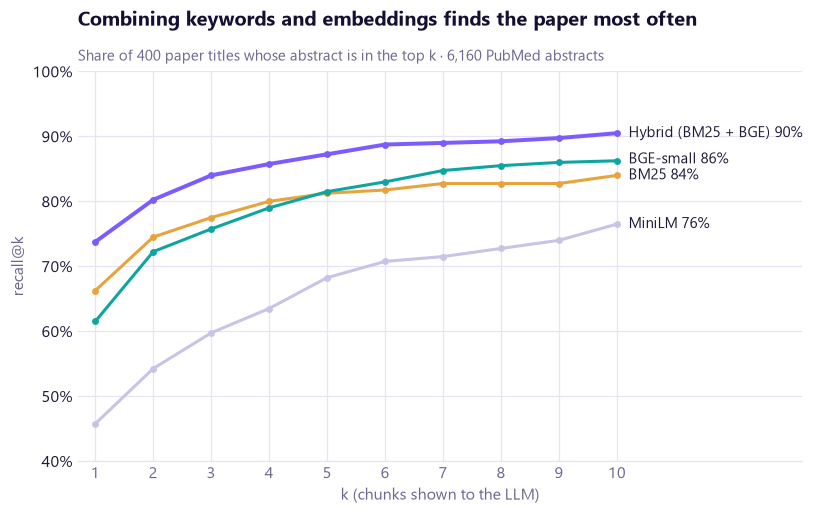

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ks = np.arange(1, 11)
ends = []
for name, ranked in pub_ranked.items():
    y = [R.recall_at_k(ranked, gold, k) for k in ks]
    ax.plot(ks, y, color=METHOD_COLOR[name], lw=2.6 if "Hybrid" in name else 2, marker="o", ms=3.5)
    ends.append((f"{name} {y[-1]:.0%}", y[-1]))
end_labels(ax, 10.2, ends)
ax.set(xlabel="k (chunks shown to the LLM)", ylabel="recall@k", xticks=ks, xlim=(0.7, 13.2), ylim=(0.4, 1.0))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.grid(axis="y")
ax.set_title("Combining keywords and embeddings finds the paper most often")
subtitle(ax, "Share of 400 paper titles whose abstract is in the top k · 6,160 PubMed abstracts")
viz.save(fig, "13_1_recall_at_k_pubmed")
plt.show()

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

The hybrid (violet) line is on top from k = 1 onwards. With k = 5 chunks it finds the right abstract for **87%** of titles, against ~81% for either method alone.

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Hybrid fusion and re-ranking</b>

**Reciprocal rank fusion (RRF)** merges two rankings using only **positions**: each chunk scores Σ 1 / (60 + rank). BM25 scores (0–50) and cosine scores (0–1) are on different scales, and ranks sidestep that problem.

A **cross-encoder** re-ranker reads the query and a chunk **together** in one transformer (full attention between the two), so it judges relevance more finely than a bi-encoder, but it must run once **per pair**. So it is used to **re-order** the top 30 from a fast retriever, never to search everything.

</div>

In [8]:
sub = slice(0, 100)            # the cross-encoder is slow on CPU, so it is tested on the first 100 queries
t0 = time.time()
rr = [ret.ranked(t, "hybrid", k=10, source="pubmed", rerank=True, qemb=qe(j)) for j, t in enumerate(titles[sub])]
rr_ms = (time.time() - t0) / 100 * 1000
rows = [{"method": "Hybrid (BM25 + BGE)", "recall@1": R.recall_at_k(pub_ranked["Hybrid (BM25 + BGE)"][sub], gold[sub], 1),
         "recall@5": R.recall_at_k(pub_ranked["Hybrid (BM25 + BGE)"][sub], gold[sub], 5), "MRR": R.mrr(pub_ranked["Hybrid (BM25 + BGE)"][sub], gold[sub]),
         "ms per query": pub_time["Hybrid (BM25 + BGE)"]},
        {"method": "Hybrid + re-rank", "recall@1": R.recall_at_k(rr, gold[sub], 1), "recall@5": R.recall_at_k(rr, gold[sub], 5),
         "MRR": R.mrr(rr, gold[sub]), "ms per query": rr_ms}]
rerank_pub = pd.DataFrame(rows)
show(rerank_pub, "Re-ranking the hybrid top 30 (first 100 title queries)", precision=3)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

method,recall@1,recall@5,MRR,ms per query
Hybrid (BM25 + BGE),0.740,0.890,0.808,43.313
Hybrid + re-rank,0.680,0.860,0.761,"3,118.287"


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- Surprise: **re-ranking made things worse here** (recall@1 74% → 68%), and it costs **~3 seconds per query** on CPU (30 transformer passes).
- The reason is a mismatch: this cross-encoder was trained on **web search questions** (MS MARCO), not on paper titles matched to biomedical abstracts.
- Lesson: a "stronger" component is not automatically better. **Measure it on your own data** (section E tests it on real questions).

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## E · Test 2 · 30 real questions about the drug labels

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · A checkable question set and metadata filters</b>

Written the way a rep or analyst would ask (*"Should women on the pill use extra contraception when starting Zepbound?"*), deliberately **not** in the label's wording.
A chunk counts as correct if it is from the **right brand's label**, the **right section**, and contains an **evidence phrase** (here: *oral contraceptive*), so correctness is checked by code, not by opinion. See `eval_questions.py`.

**Metadata filter**: if the question names a brand, search only that brand's chunks. Semaglutide's three labels (Ozempic, Wegovy, Rybelsus) share whole paragraphs, so a retriever can return the right fact from the **wrong drug's label**, a serious error for a compliance-sensitive answer.

</div>

In [9]:
lg = E.label_gold(kb)
runs = [("BM25", False), ("MiniLM", False), ("BGE-small", False), ("Hybrid (BM25 + BGE)", False), ("Hybrid + re-rank", False),
        ("BGE-small", True), ("Hybrid + re-rank", True)]
label_ranked, rows = {}, []
for name, filt in runs:
    meth, rerank = METHOD_KEY[name]
    ranked = [ret.ranked(r.question, meth, k=10, source="label", brand=r.brand if filt else None, rerank=rerank) for r in lg.itertuples()]
    label_ranked[(name, filt)] = ranked
    rows.append({"method": name, "brand filter": "yes" if filt else "no",
                 "recall@1": R.recall_at_k(ranked, lg["gold"], 1), "recall@3": R.recall_at_k(ranked, lg["gold"], 3),
                 "recall@5": R.recall_at_k(ranked, lg["gold"], 5), "MRR": R.mrr(ranked, lg["gold"]),
                 "top-1 from right brand": np.mean([kb.at[x[0], "brand"] == b for x, b in zip(ranked, lg["brand"])])})
label_table = pd.DataFrame(rows)
show(label_table, "30 label questions · 798 label chunks (each question = 3.3 points)", precision=3)

method,brand filter,recall@1,recall@3,recall@5,MRR,top-1 from right brand
BM25,no,0.600,0.700,0.733,0.658,0.867
MiniLM,no,0.633,0.733,0.833,0.714,0.933
BGE-small,no,0.700,0.900,0.933,0.808,1.000
Hybrid (BM25 + BGE),no,0.700,0.900,0.967,0.806,0.967
Hybrid + re-rank,no,0.767,0.900,0.933,0.831,0.967
BGE-small,yes,0.700,0.900,0.933,0.808,1.000
Hybrid + re-rank,yes,0.767,0.933,0.933,0.839,1.000


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **BGE-small** puts a correct passage in the top 5 for **28 of 30** questions (93%), against 22 for BM25 (73%).
- **Hybrid** reaches 29/30 at k = 5, and **re-ranking** helps rank 1 here: 23 vs 21 questions answered by the first chunk. These are real questions, the kind the cross-encoder was trained on. The gaps are only 1–2 questions, though, so treat them as a tendency, not a proof.
- **Wrong-brand risk**: BM25's first chunk came from the **wrong drug's label** in 4 of 30 questions (13%). BGE was always right because every question names its brand.
- The **brand filter** did not change the scores on this set, but it *guarantees* the right brand in every case, at no cost. In the product, any question naming a drug will be filtered. **Setup chosen for notebook 14: hybrid + re-rank + brand filter.**

</div>

In [10]:
best = label_ranked[("Hybrid + re-rank", True)]
miss = [{"question": r.question, "top-1 retrieved": kb.at[best[j][0], "title"], "starts with": kb.at[best[j][0], "text"][:110],
         "rank of first correct": next((i + 1 for i, x in enumerate(best[j]) if x in r.gold), "not in top 10")}
        for j, r in enumerate(lg.itertuples()) if best[j][0] not in r.gold]
show(pd.DataFrame(miss), "Questions where the best setup's top-1 chunk is not a correct one")

question,top-1 retrieved,starts with,rank of first correct
Does Foundayo need to be taken on an empty stomach?,Foundayo label · 8 Use in Specific Populations,"a clinical trial. Because delayed gastric emptying may affect the absorption of oral medications, advise patie",not in top 10
What are the most common side effects reported with Wegovy?,Wegovy label · 10 Overdosage,10 OVERDOSAGE Overdoses have been reported with other GLP-1 receptor agonists. Effects have included severe na,3
Which pen strengths does Ozempic come in?,Ozempic label · 5 Warnings and Precautions,"retinopathy (OZEMPIC 0.7%, placebo 0.4%). Rapid improvement in glucose control has been associated with a temp",2
What happens if a patient takes too much Mounjaro?,Mounjaro label · 5 Warnings and Precautions,)] . Monitor renal function in patients reporting adverse reactions to MOUNJARO that could lead to volume depl,not in top 10
Does Saxenda speed up the heart rate?,Saxenda label · 5 Warnings and Precautions,"study visits for 0.9% and 0.3%, respectively. Tachycardia was reported as an adverse reaction in 0.6% of SAXEN",2
Does Saxenda cause kidney problems from dehydration?,Saxenda label · 5 Warnings and Precautions,Adverse Reactions ( 6.2 )] . The majority of the reported events occurred in patients who had experienced gast,3
What is the first dose of Victoza and how is it titrated?,Victoza label · 14 Clinical Studies,"During the titration period, doses of metformin and glimepiride were to be increased up to 2,000 mg/day and 4",2


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- In 5 of these 7 cases a correct chunk is at **rank 2–3**, so the LLM still sees it in the top 5.
- **Real misses** are *"Does Foundayo need to be taken on an empty stomach?"* and *"What happens if a patient takes too much Mounjaro?"*. The retriever returned the gastric-emptying passage and the warnings section: topically close, but not the answer. Questions whose key words also appear in many other passages (*stomach*, *too much*) are the hard ones.
- *"Which pen strengths…"* first returned a retinopathy paragraph, a reminder that embeddings can rank something unrelated first when the query is short.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## F · Test 3 · Searching informal visit notes

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · precision@10 on labels by construction</b>

Analysts will ask things like *"show me notes where doctors complain about cost"*. Our synthetic notes carry the **objection labels they were generated with** (notebook 09), so for 7 objection queries we can count how many of the **top 10** notes really have that objection (**precision@10**).
Notes are short, abbreviated and full of synonyms (*copay*, *PA*, *not covered*), which is a different test from formal label text.

</div>

In [11]:
ng = E.note_gold(kb)
note_prec = pd.DataFrame({name: [len(set(ret.ranked(r.question, METHOD_KEY[name][0], k=10, source="note")) & r.gold) / 10
                                 for r in ng.itertuples()] for name in ["BM25", "MiniLM", "BGE-small", "Hybrid (BM25 + BGE)"]},
                         index=ng["objection"])
display(show(note_prec.reset_index().assign(query=ng["question"].values), "precision@10 per objection query", precision=1))
show(note_prec.mean().rename("mean precision@10").reset_index().rename(columns={"index": "method"}), "Average over 7 queries", precision=3)

objection,BM25,MiniLM,BGE-small,Hybrid (BM25 + BGE),query
cost_coverage,0.2,0.9,1.0,0.6,doctor says patients can't afford it or insurance won't cover it
gi_tolerability,0.9,0.6,0.7,0.6,physician worried about stomach upset and vomiting
elderly_frailty,1.0,1.0,1.0,1.0,concern about using it in frail older patients
efficacy_vs_comp,1.0,0.3,0.4,0.9,doctor thinks the competitor works better
injection_aversion,0.3,0.9,0.7,0.8,patients don't want needles
supply_access,1.0,1.0,1.0,1.0,pharmacies are out of stock
safety_other,1.0,1.0,1.0,1.0,worried about pancreatitis or thyroid safety


method,mean precision@10
BM25,0.771
MiniLM,0.814
BGE-small,0.829
Hybrid (BM25 + BGE),0.843


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **On average, the embeddings beat keywords** (BGE 0.83, MiniLM 0.81, BM25 0.77), and **hybrid is best** (0.84).
- But the per-query picture matters more than the average (chart below).

</div>

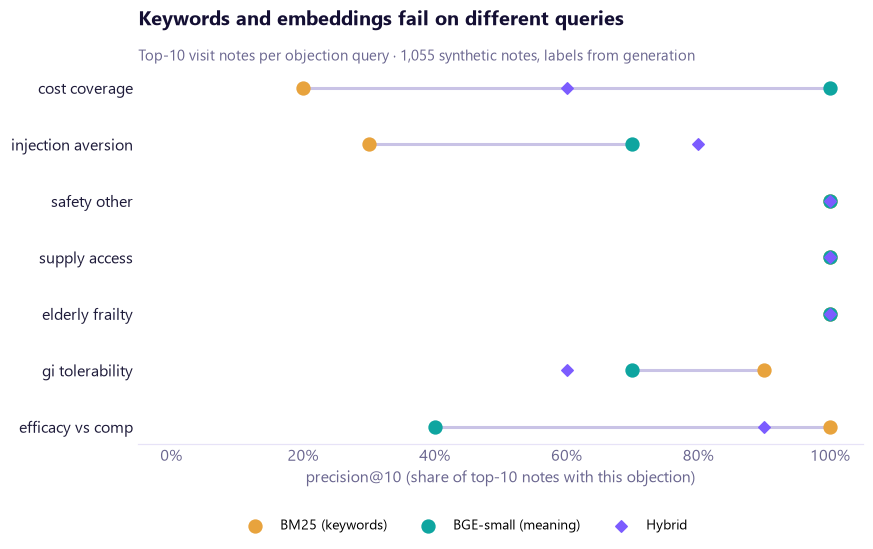

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
order = note_prec["BGE-small"].sub(note_prec["BM25"]).sort_values().index
y = np.arange(len(order))
for o, yi in zip(order, y):
    ax.plot([note_prec.at[o, "BM25"], note_prec.at[o, "BGE-small"]], [yi, yi], color=MUTED, lw=2, zorder=1)
ax.scatter(note_prec.loc[order, "BM25"], y, color=METHOD_COLOR["BM25"], s=70, zorder=2, label="BM25 (keywords)")
ax.scatter(note_prec.loc[order, "BGE-small"], y, color=METHOD_COLOR["BGE-small"], s=70, zorder=3, label="BGE-small (meaning)")
ax.scatter(note_prec.loc[order, "Hybrid (BM25 + BGE)"], y, color=METHOD_COLOR["Hybrid (BM25 + BGE)"], s=28, marker="D", zorder=4, label="Hybrid")
ax.set(yticks=y, yticklabels=[o.replace("_", " ") for o in order], xlim=(-0.05, 1.05), xlabel="precision@10 (share of top-10 notes with this objection)")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.17), ncol=3, frameon=False, fontsize=9)
ax.set_title("Keywords and embeddings fail on different queries")
subtitle(ax, "Top-10 visit notes per objection query · 1,055 synthetic notes, labels from generation")
viz.save(fig, "13_2_note_search_precision")
plt.show()

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **Cost** (BM25 20% → BGE 100%): the query says *afford*, a word no note uses. The notes say *cost*, *coverage*, *PA*. **Needles** (30% → 70%): only 4 notes say *needle*; they say *injection*. Embeddings bridge the synonyms.
- **Competitor efficacy** is the reverse (BM25 100%, BGE 40%). Here the notes use the query's own words (*better*, *works*), while the embedding confuses *comparing drugs* with *any discussion of drugs*.
- **Hybrid** is best or near-best on 5 of 7 queries but is dragged down on two (cost 60%, GI 60%). It averages highest and never collapses the way BM25 does on cost (20%), so it is the safest default when we cannot predict how a user will phrase things.
- Three queries are perfect for every method: easy topics with distinctive words (*frail*, *out of stock*, *pancreatitis*).

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## G · Does chunk size matter?

</div>

In [13]:
rows = []
for size in [100, 200, 400]:
    ch = K.label_chunks(size=size, overlap=size // 5).reset_index(drop=True)
    e = R.embed_texts(ch["text"].tolist(), "bge")
    g = E.label_gold(ch)
    qv = R.embed_texts(g["question"].tolist(), "bge", query=True)
    ranked = [list(np.argsort(-(e @ v))[:10]) for v in qv]
    words = ch["text"].str.split().str.len()
    rows.append({"chunk words": size, "chunks": len(ch), "recall@1": R.recall_at_k(ranked, g["gold"], 1),
                 "recall@5": R.recall_at_k(ranked, g["gold"], 5), "MRR": R.mrr(ranked, g["gold"]),
                 "words the LLM reads in top 5": 5 * int(words.median())})
show(pd.DataFrame(rows), "BGE-small on the 30 label questions, three chunk sizes (overlap = 20%)", precision=3)

chunk words,chunks,recall@1,recall@5,MRR,words the LLM reads in top 5
100,"1,552",0.633,0.867,0.742,500
200,798,0.700,0.933,0.808,"1,000"
400,430,0.767,0.933,0.839,"2,000"


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **Bigger chunks scored higher** (recall@1 63% → 70% → 77%), partly because a bigger chunk is more likely to *contain* the evidence phrase, so the test favours them.
- The cost is context: the LLM would read **2,000 words** for 5 chunks of 400, against 1,000 at 200, and more irrelevant text means more room for a wrong answer. Also, BGE reads only ~512 tokens (~380 words), so the end of a 400-word chunk is never embedded.
- **We keep 200 words**: recall@5 is the same as with 400 (93%), at half the reading.

</div>

In [14]:
C.save_metrics("nb13_retrieval", {
    "pubmed_title_to_abstract": pub_table.to_dict("records"), "pubmed_rerank_first100": rerank_pub.to_dict("records"),
    "label_questions": label_table.to_dict("records"), "note_precision_at_10": note_prec.round(3).to_dict(),
})
print("saved reports/evaluation/nb13_retrieval.json")

saved reports/evaluation/nb13_retrieval.json


<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## H · Summary

</div>

<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Limitations</b>

1. **Small question sets**: 30 label questions and 7 note queries, so one question is worth 3.3 points (label set) or a whole query (note set). Differences of 1–2 questions are not significant. A larger hand-checked set is a good next step.
2. **Title → abstract favours keywords** (shared exact words) compared with real questions.
3. **Labels**: Ozempic and Wegovy come from repackager copies, and Wegovy's is from April 2024. A production system must use each manufacturer's current label (DailyMed) and refresh it.
4. **Visit notes are synthetic** (notebook 09), so real notes will be messier.
5. The re-ranker is a **general web model**. A biomedical cross-encoder, or fine-tuning on our own pairs, could change the verdict.

</div>

<div style="border-left:6px solid #10B981; background:#EAFBF1; color:#065F46; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">🎯 Key takeaways</b>

**Done:** a searchable knowledge base of **8,013 chunks** (labels, papers, notes) with metadata, and a measured retriever. **Hybrid (BM25 + BGE) is the most robust**: recall@5 87% on papers, 29/30 label questions in the top 5. Re-ranking helps real questions but not title matching, and the brand filter guarantees the right label.
**Next:** notebook 14, **RAG**: give the top chunks to an open LLM, write a pre-visit brief **with citations**, and measure whether answers stay faithful to the sources.

**Interview questions you can now answer**
- *Bi-encoder vs cross-encoder?* Bi-encoder: embed query and passage separately, fast, used for search. Cross-encoder: reads both together, more accurate, too slow for search, used to re-rank the top 30.
- *Why hybrid search?* Keywords catch exact names and codes, embeddings catch synonyms. They fail on different queries, and RRF fuses their ranks without mixing score scales.
- *How do you choose chunk size?* Trade recall against how much text the LLM reads. Respect the embedding model's token limit, and use overlap so sentences aren't cut.
- *How do you evaluate retrieval without labels?* Build checkable sets: title → abstract, questions with evidence phrases, labels by construction. Report recall@k and MRR.
- *When do you need an ANN index (HNSW)?* At millions of vectors. At 8k, exact search takes under 0.1 ms.
- *Why metadata filters?* So a Zepbound question can never be answered from Ozempic's label: correctness and compliance.

</div>